# Activity 4.1 · Measure the Karate Club in Python
**Chapter 4 · Social Network Analytics I** · in class · pairs · about 30 minutes

**Goal:** compute **every measure from this chapter** on one real social network — and see what each command does.
**Data:** Zachary’s karate club, built into networkx: 34 members, 78 friendships, observed in the 1970s. The club split into two groups after a conflict between the instructor (**node 0**, “Mr. Hi”) and the administrator (**node 33**, “Officer”).

📖 Interactive study guide: [Chapter 4](https://mehrdadjalali-ai.github.io/SocialMediaAnayltics/interactive/Chapter4_Networks_Influence_Communities.html)

**How to work**
1. Run the cells **from top to bottom** (`Shift + Enter`). Every command is explained in the comment next to it.
2. At each **🔁 Try it** box, change **one value**, run the cell again and look at what changes. That is all — no new code needed.
3. Write your answers to the **five activity questions** at the end.

## 0 · Setup
| Command | What it does |
|---|---|
| `import networkx as nx` | the Python library for networks: build graphs, compute measures, find communities |
| `import pandas as pd` | tables — we put the measures into a DataFrame to sort and compare them |
| `import matplotlib.pyplot as plt` | draws the pictures |
| `SEED = 42` | a fixed random seed: layouts and Louvain give the **same result every time** |

In [2]:
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUTD = ROOT / "data", ROOT / "outputs"
OUTD.mkdir(exist_ok=True)
SEED = 42
import pandas as pd, networkx as nx, matplotlib.pyplot as plt

## 1 · Load the network and look inside
A graph `G` has **nodes** (members) and **edges** (friendships). Both can carry **attributes**: each node has a `club`, each edge a `weight` (how many activities the two members shared).

In [4]:
G = nx.karate_club_graph()                    # load the built-in karate club network (undirected, weighted)
print(G)                                      # short summary: type, number of nodes and edges
print("nodes:", G.number_of_nodes())          # 34 members with method number_of_nodes()
print("edges:", G.number_of_edges())          # 78 friendships
print("node 0:", G.nodes[0])                  # attributes of one node  -> {'club': 'Mr. Hi'}
print("edge 0–1:", G.edges[0, 1])             # attributes of one edge  -> {'weight': 4}
print("friends of 0:", list(G.neighbors(0)))  # all direct neighbours of node 0

Graph named "Zachary's Karate Club" with 34 nodes and 78 edges
nodes: 34
edges: 78
node 0: {'club': 'Mr. Hi'}
edge 0–1: {'weight': 4}
friends of 0: [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31]


## 2 · Three ways to represent the same graph
**Edge list** (one row per tie — how we store and share networks) · **adjacency list** (each node and its neighbours — how networkx works inside) · **adjacency matrix** (n × n table of 0/1 — mostly zeros for social networks).

In [ ]:
edges = nx.to_pandas_edgelist(G)               # edge list as a table: source, target, weight
print(edges.head())
print("\nadjacency list (first 3 lines):")
for line in list(nx.generate_adjlist(G))[:3]:  # each line: a node, then its neighbours
    print(line)
A = nx.to_numpy_array(G, weight=None)          # adjacency matrix: 1 = tie, 0 = no tie
print("\nmatrix shape:", A.shape, "· share of cells that are 1:", round(A.mean(), 3))

   source  target  weight
0       0       1       4
1       0       2       5
2       0       3       3
3       0       4       3
4       0       5       3

adjacency list (first 3 lines):
0 1 2 3 4 5 6 7 8 10 11 12 13 17 19 21 31
1 2 3 7 13 17 19 21 30
2 3 7 8 9 13 27 28 32

matrix shape: (34, 34) · share of cells that are 1: 0.135


## 3 · Draw the network
`spring_layout` places connected nodes close together. The `seed` makes the picture reproducible. Colour = club after the split, size = number of ties.

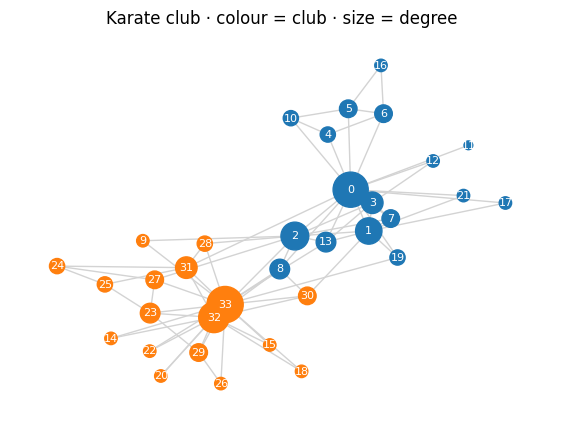

In [7]:
pos = nx.spring_layout(G, seed=3)

#pos = nx.kamada_kawai_layout(G)       # Kamada–Kawai: picture distance ≈ steps in the network — clean for small graphs
#pos = nx.circular_layout(G)           # Circular: all nodes on one ring — easy to see ties across the circle                               # x/y position for every node; seed = same picture every run
club_color = ["tab:blue" if G.nodes[n]["club"] == "Mr. Hi" else "tab:orange" for n in G]
deg = dict(G.degree())                                              # number of ties per node
plt.figure(figsize=(7, 5))
nx.draw_networkx(G, pos, node_color=club_color, node_size=[40 * deg[n] for n in G],
                 edge_color="lightgrey", font_size=8, font_color="white")
plt.title("Karate club · colour = club · size = degree"); plt.axis("off"); plt.show()

> 🔁 **Try it:** change `seed=3` to `seed=7` and run again. The **picture** changes — do the **ties** change? (No: a layout is only a drawing. Never read meaning from distances on the picture.)

## 4 · Describe the whole network
| Command | Measures |
|---|---|
| `nx.density(G)` | share of all possible ties that exist: m / [n(n − 1)/2] |
| average degree | 2m / n — ties per member |
| `nx.average_clustering(G)` | how often a member’s friends are also friends |
| `nx.number_connected_components(G)` | how many separate pieces |
| `nx.diameter(G)` | the longest of all shortest paths |
| `nx.average_shortest_path_length(G)` | average number of steps between two members |

In [8]:
n, m = G.number_of_nodes(), G.number_of_edges()
print("density            :", round(nx.density(G), 3))                    # 3 is number of decimal
print("average degree     :", round(2 * m / n, 2))                         # 4.59
print("average clustering :", round(nx.average_clustering(G), 3))          # 0.571
print("components         :", nx.number_connected_components(G))           # 1 — everyone can reach everyone
print("diameter           :", nx.diameter(G))                              # 5 steps
print("avg. path length   :", round(nx.average_shortest_path_length(G), 2))  # 2.41 steps
clust = nx.clustering(G)                                                    # clustering of every single node
print("clustering of node 0 vs node 33:", round(clust[0], 2), round(clust[33], 2))

density            : 0.139
average degree     : 4.59
average clustering : 0.571
components         : 1
diameter           : 5
avg. path length   : 2.41
clustering of node 0 vs node 33: 0.15 0.11


> 🔁 **Try it:** print `clust[4]` and `clust[2]`. Which one lives in a **closed** friend circle, and which one **connects** groups?

## 5 · Traversal: BFS, DFS and shortest paths
**BFS** visits all friends first, then friends of friends (level = distance). **DFS** goes as deep as possible, then steps back.

In [ ]:
start = 0                                                         # start node — change me
levels = list(nx.bfs_layers(G, [start]))                          # BFS: list of levels (level k = k steps away)
for k, lvl in enumerate(levels):
    print(f"level {k}: {len(lvl):2d} members  {sorted(lvl)[:10]}{' …' if len(lvl) > 10 else ''}")
print("\nBFS visit order:", list(nx.bfs_tree(G, start))[:12], "…")              # # only the first 12 nodes
print("DFS visit order:", list(nx.dfs_preorder_nodes(G, start))[:12], "…")       # depth first
print("\nshortest path 16 → 26:", nx.shortest_path(G, 16, 26))                 # one shortest path
print("distance 16 → 26:", nx.shortest_path_length(G, 16, 26), "steps")

level 0:  1 members  [0]
level 1: 16 members  [1, 2, 3, 4, 5, 6, 7, 8, 10, 11] …
level 2:  9 members  [9, 16, 24, 25, 27, 28, 30, 32, 33]
level 3:  8 members  [14, 15, 18, 20, 22, 23, 26, 29]

BFS visit order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12] …
DFS visit order: [0, 1, 2, 3, 7, 12, 13, 33, 8, 30, 32, 14] …

shortest path 16 → 26: [16, 5, 0, 8, 33, 26]
distance 16 → 26: 5 steps


> 🔁 **Try it:** set `start = 16` (a member at the edge of the club) and run again. How many levels are there now — and why?

## 6 · Four centralities
| Command | Question it answers |
|---|---|
| `nx.degree_centrality(G)` | who has the **most ties**? (degree / (n − 1)) |
| `nx.betweenness_centrality(G)` | who sits **on the shortest paths** between others? |
| `nx.closeness_centrality(G)` | who is **nearest to everyone**? ((n − 1) / sum of distances) |
| `nx.pagerank(G)` | who is tied to **important** nodes? (uses the edge weights) |

In [ ]:
cent = pd.DataFrame({
    "degree":      dict(G.degree()),                    # raw number of ties
    "betweenness": nx.betweenness_centrality(G),        # normalised 0–1
    "closeness":   nx.closeness_centrality(G),
    "pagerank":    nx.pagerank(G),                      # weighted by "weight"
}).round(3)
for col in cent.columns:                                 # top 5 for every measure
    print(f"{col:12s}", list(cent[col].sort_values(ascending=False).index[:5]))
cent.loc[[0, 33, 2, 31]]                                 # the two leaders, one bridge (2) and the "odd" node 31

degree       [33, 0, 32, 2, 1]
betweenness  [0, 33, 32, 2, 31]
closeness    [0, 2, 33, 31, 13]
pagerank     [33, 0, 32, 2, 1]


,degree,betweenness,closeness,pagerank
0,16,0.438,0.569,0.089
33,17,0.304,0.550,0.097
2,10,0.144,0.559,0.063
31,6,0.138,0.541,0.042


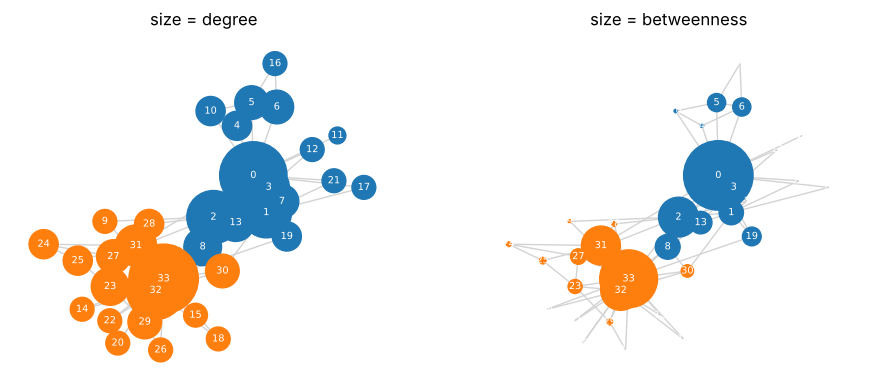

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col in zip(axes, ["degree", "betweenness"]):
    size = 2500 * cent[col] / cent[col].max()            # node size = the measure
    nx.draw_networkx(G, pos, ax=ax, node_color=club_color, node_size=size, edge_color="lightgrey",
                     font_size=7, font_color="white")
    ax.set_title(f"size = {col}"); ax.axis("off")
plt.show()

> 🔁 **Try it:** change `["degree", "betweenness"]` to `["closeness", "pagerank"]` and run again. Look at **node 31**: only 6 ties — where does it rank now?

## 7 · Bridges and brokers
A **bridge** is a tie whose removal splits the network. The karate club has only one: `(0, 11)` — node 11 has a single friend. **No** tie on its own separates the two groups — but a few ties **cross between them**, and a few members hold them.

In [ ]:
print("true bridges:", list(nx.bridges(G)))                                    # [(0, 11)] — node 11 has only one friend
cross = [(u, v) for u, v in G.edges() if G.nodes[u]["club"] != G.nodes[v]["club"]]
print("ties between the two groups:", len(cross), "of", G.number_of_edges())   # 11 of 78
brokers = pd.Series([x for e in cross for x in e]).value_counts()              # who holds the cross-group ties?
print("members with most cross-group ties:\n", brokers.head(4).to_string())
print("local bridges (ends share no friend):", [(u, v) for u, v, span in nx.local_bridges(G) if span != float("inf")][:6])

true bridges: [(0, 11)]
ties between the two groups: 11 of 78
members with most cross-group ties:
 2     4
8     3
33    3
30    2
local bridges (ends share no friend): [(0, 31), (1, 30), (2, 9), (2, 27), (2, 28), (9, 33)]


## 8 · Communities and modularity
**Louvain** tries many splits and keeps the one with the **highest modularity Q** (ties inside groups minus what chance would give). We also try two other methods from the slides.

resolution 1.0: 4 communities · modularity Q = 0.427
club       Mr. Hi  Officer
community                 
0               6        0
1              10        0
2               0        4
3               1       13


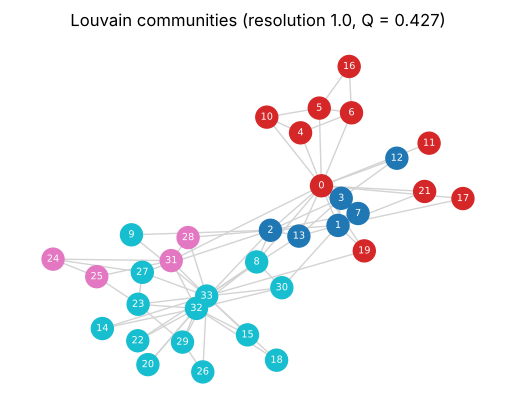

In [ ]:
res = 1.0                                                                  # resolution — change me
comms = nx.community.louvain_communities(G, seed=SEED, resolution=res)     # list of sets, one set per community
Q = nx.community.modularity(G, comms)                                      # quality of this split
print(f"resolution {res}: {len(comms)} communities · modularity Q = {Q:.3f}")
comm_of = {n: i for i, c in enumerate(comms) for n in c}                   # node -> community number
print(pd.crosstab(pd.Series(comm_of, name="community"),                    # compare with the real split
                  pd.Series(nx.get_node_attributes(G, "club"), name="club")))
nx.draw_networkx(G, pos, node_color=[comm_of[n] for n in G], cmap="tab10", node_size=250,
                 edge_color="lightgrey", font_size=7, font_color="white")
plt.title(f"Louvain communities (resolution {res}, Q = {Q:.3f})"); plt.axis("off"); plt.show()

In [ ]:
lp = list(nx.community.label_propagation_communities(G))        # every node takes its neighbours' most common label
gn = next(nx.community.girvan_newman(G))                         # remove highest-betweenness ties until the graph splits once
for name, part in [("Label propagation", lp), ("Girvan–Newman, first split", gn)]:
    print(f"{name:28s} {len(part)} groups · Q = {nx.community.modularity(G, part):.3f}")

Label propagation            3 groups · Q = 0.309
Girvan–Newman, first split   2 groups · Q = 0.348


> 🔁 **Try it:** set `res = 0.5`, then `res = 2.0`, and run the Louvain cell again. How many communities do you get, and what happens to Q? (Communities are a **choice** — always report the resolution.)

## 9 · Homophily: assortativity
**Assortativity** runs from −1 (ties connect *different* nodes) through 0 (random) to +1 (ties connect *similar* nodes).

In [ ]:
print("by club  :", round(nx.attribute_assortativity_coefficient(G, "club"), 3))   # +0.718: members tie within their group
print("by degree:", round(nx.degree_assortativity_coefficient(G), 3))              # −0.476: hubs tie to low-degree members
inside = len(G.edges()) - len(cross)
print(f"ties inside the same club: {inside} of {G.number_of_edges()} ({inside / G.number_of_edges():.0%})")

by club  : 0.718
by degree: -0.476
ties inside the same club: 67 of 78 (86%)


## 10 · Link prediction
For pairs that are **not yet connected**: how many friends do they share? `jaccard_coefficient` divides by all friends of both; `adamic_adar_index` gives more weight to shared friends who have **few** friends.

In [ ]:
pairs = [(0, 33), (2, 33), (5, 6)]                              # pairs to score — change me (pairs that are already tied are skipped)
pairs = [p for p in pairs if not G.has_edge(*p)]
cn = {p: len(list(nx.common_neighbors(G, *p))) for p in pairs}
ja = {(u, v): s for u, v, s in nx.jaccard_coefficient(G, pairs)}
aa = {(u, v): s for u, v, s in nx.adamic_adar_index(G, pairs)}
print(pd.DataFrame({"common neighbours": cn, "Jaccard": ja, "Adamic–Adar": aa}).round(2))
top = sorted(nx.adamic_adar_index(G), key=lambda x: -x[2])[:5]   # best-scored new ties in the whole club
print("\ntop 5 predicted ties:", [(u, v, round(s, 2)) for u, v, s in top])

      common neighbours  Jaccard  Adamic–Adar
0 33                  4     0.14         2.71
2 33                  6     0.29         4.72

top 5 predicted ties: [(2, 33, 4.72), (0, 33, 2.71), (1, 33, 2.25), (4, 5, 1.99), (6, 10, 1.99)]


> 🔁 **Try it:** add the pair `(23, 24)` to `pairs` and run again. Then look at the row `(0, 33)`: the two **leaders** share 4 friends but were never tied — what does the network *not* know about them?

## 11 · Node classification
We pretend we only know the club of the two leaders, **0 and 33**, and let the labels **flow through the network** to everyone else.

In [ ]:
from networkx.algorithms import node_classification
H = G.copy()
H.nodes[0]["label"], H.nodes[33]["label"] = "Mr. Hi", "Officer"     # only two known labels
pred = node_classification.local_and_global_consistency(H)          # label spreading
truth = [G.nodes[n]["club"] for n in G]
wrong = [n for n, (p, t) in enumerate(zip(pred, truth)) if p != t]
print(f"correct: {len(G) - len(wrong)} of {len(G)} · wrong: {wrong}")   # 33 of 34 · node 8
print("node 8's friends and their club:", {v: G.nodes[v]["club"] for v in G.neighbors(8)})

correct: 33 of 34 · wrong: [8]
node 8's friends and their club: {0: 'Mr. Hi', 2: 'Mr. Hi', 30: 'Officer', 32: 'Officer', 33: 'Officer'}


## 12 · Save for Gephi (Lab 4.2)
We store the measures and communities as **node attributes** and export a **GEXF** file. In Lab 4.2 you open it in Gephi and compare Gephi’s numbers with these.

In [ ]:
for col in cent.columns:
    nx.set_node_attributes(G, cent[col].to_dict(), col)             # degree, betweenness, closeness, pagerank
nx.set_node_attributes(G, comm_of, "community")                       # Louvain community number
nx.write_gexf(G, OUTD / "karate_ch4.gexf")
print("saved:", OUTD / "karate_ch4.gexf")

saved: /home/claude/socialmediaanayltics/outputs/karate_ch4.gexf


## ✍️ Activity questions — answer in 1–2 sentences each
1. **Whole network:** density 0.139 and clustering 0.571 — what do these two numbers tell you about the club?
2. **Traversal:** from node 0, how many members are 1 step away? From node 16, how many steps to the farthest member?
3. **Centralities:** node 31 has only 6 ties. Why does it rank high on betweenness?
4. **Communities:** how many communities did you get at resolution 0.5 and at 2.0? Which one would you report, and why?
5. **Link prediction:** the leaders 0 and 33 share friends but have no tie. What does that tell you about the limits of link prediction?

_Your answers:_